In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [1]:
from cwfc.targets import load_cpu_readings, build_targets, split_train_holdout

cpu = load_cpu_readings("../challenge_data")
targets = build_targets(cpu)                  # full series first
train, holdout = split_train_holdout(targets) # then the split

print(targets.shape, train.shape, holdout.shape)
print("train:  ", train.index[0], "->", train.index[-1])
print("holdout:", holdout.index[0], "->", holdout.index[-1])
print(targets.describe())

(134, 2) (110, 2) (24, 2)
train:   0 -> 32700
holdout: 33000 -> 39900
       active_vm_count  aggregate_cpu_utilization
count            134.0                 134.000000
mean           10000.0                   9.388101
std                0.0                   0.194987
min            10000.0                   8.983613
25%            10000.0                   9.250956
50%            10000.0                   9.367252
75%            10000.0                   9.485657
max            10000.0                   9.912175


In [4]:
assert len(targets) == 134
assert targets.isna().sum().sum() == 0                  # no gaps on this release
assert (targets["active_vm_count"] == 10_000).all()
assert targets["aggregate_cpu_utilization"].between(0, 100).all()
assert (np.diff(targets.index) == 300).all()

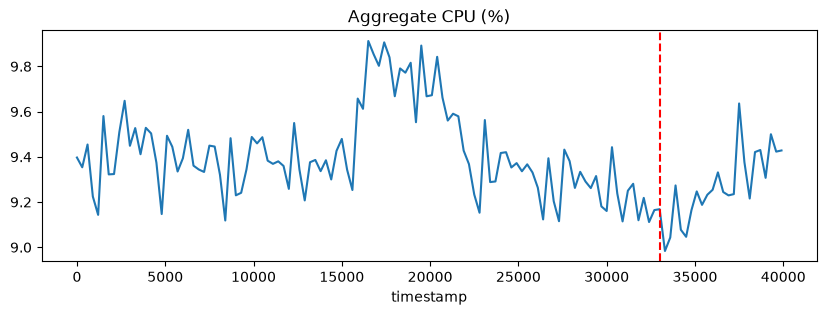

In [5]:
import matplotlib.pyplot as plt
ax = targets["aggregate_cpu_utilization"].plot(title="Aggregate CPU (%)", figsize=(10, 3))
ax.axvline(holdout.index[0], color="r", ls="--")
plt.savefig("../reports/figures/target_series.png", dpi=120, bbox_inches="tight")

In [10]:
v = cpu[cpu["avg_cpu"].between(0, 100)]
g = v.groupby("timestamp")
extra = pd.DataFrame({
    "fleet_p95_cpu": g["avg_cpu"].quantile(0.95),          # the hot tail, not only the mean
    "mean_max_cpu": g["max_cpu"].mean(),                   # spike pressure hidden by 5-min averages
    "pct_vms_above_50": g["avg_cpu"].apply(lambda s: (s > 50).mean() * 100),
})